In [190]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# -------------------------------------------------
# Load data
# -------------------------------------------------
MIN_TIME_THRESH = 1
MAX_TIME_THRESH = 1800
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)
from IPython.display import display, HTML
pd.options.display.float_format = "{:.1f}".format
def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html(index=False)}
    </div>
    """))
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="all")
# df = pd.read_excel(file_path, sheet_name="all-updated")
df = df.rename(columns=lambda c: c.replace("-total", ""))
df = clean_dataframe(df)

all_algos=[
    'kPEX-S', 'kPEX-R', 'kPEX-P', 'kPEX-B', 'kPEX-MB',
    'UMKP-S', 'UMKP-R', 'UMKP-P', 'UMKP-B',
    'UMKP+-S', 'UMKP+-R', 'UMKP+-P', 'UMKP+-B',
    'UMKP+-oriented-S', 'UMKP+-oriented-R', 'UMKP+-oriented-P', 'UMKP+-oriented-B'
]
baseline_algos="UMKP-Imp    UMKP    kPEX-Imp        kPEX    Maple   DiseMKP kPlexT".split()
bnb_cols = [f"{algo}-bnb" for algo in all_algos]
total_cols = [f"{algo}" for algo in all_algos]

remove_rows = (
    # (df[bnb_cols] < 1).all(axis=1) |
    (df[bnb_cols] == 1800).all(axis=1)
)
# display_scroll(df[remove_rows])
df = df.loc[~remove_rows].copy()
print(df.shape)
feature_cols = "dataset	k	n	m	d_avg	d_max	core_number	shell_sizes".split()
export_df = df[feature_cols + bnb_cols + total_cols].copy()
export_df = export_df.mask(
    pd.to_numeric(export_df.stack(), errors="coerce").unstack() == 1800,
    "x"
)
export_df.to_csv("ml-data.csv", index=False)
# display(filtered_df[feature_cols + bnb_cols+total_cols])




(4283, 147)


/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_8140/1870262921.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_8140/1870262921.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_8140/1870262921.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain 

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_8140/44376492.py:35: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_work = df_work[~(vals >= max_time_thresh).all(axis=1)]


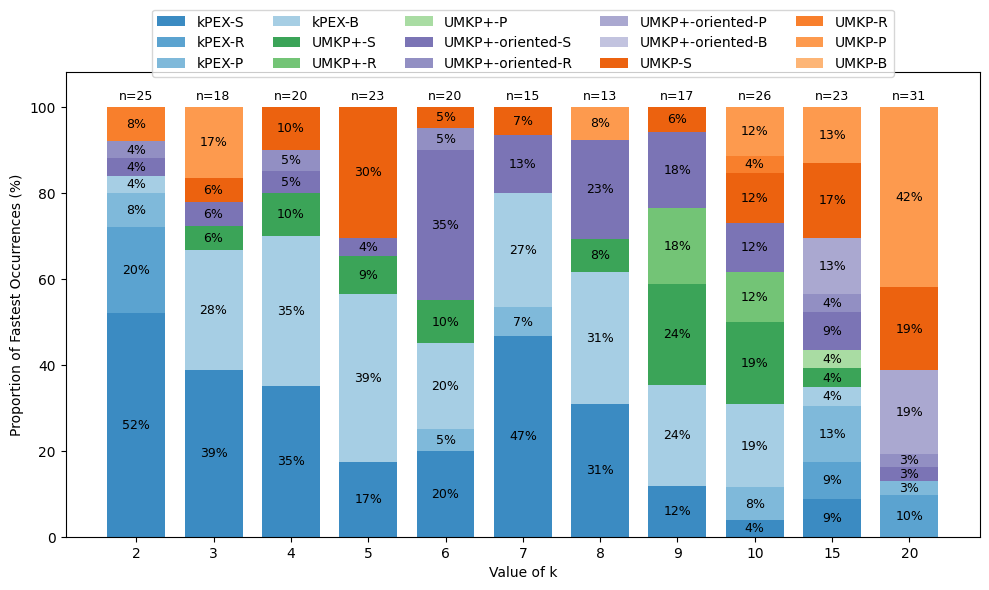

In [159]:
def plot_fastest_occurrences(
    df,
    suffix="",
    groups=None,
    k_values=None,
    min_time_thresh=1,
    max_time_thresh=1800,
    min_abs_gap=10,
    min_ratio=1.2,
    figsize=(10, 6),
    annotate_thresh=3,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    groups = [
        ['kPEX-S', 'kPEX-R', 'kPEX-P', 'kPEX-B'],
        ['UMKP+-S', 'UMKP+-R', 'UMKP+-P'],
        ['UMKP+-oriented-S', 'UMKP+-oriented-R', 'UMKP+-oriented-P', 'UMKP+-oriented-B'],
        ['UMKP-S', 'UMKP-R', 'UMKP-P', 'UMKP-B'],
    ]
    # groups += [["kPEX"], ["kPlexT"], ["Maple"], ["DiseMKP"]]
    # groups = ["UMKP-Imp UMKP".split(), "kPEX-Imp kPEX2".split(), ["kPlexT"], ["Maple"], ["DiseMKP"]]
    if k_values is None:
        k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]

    all_algos = sum(groups, [])
    cols = [f"{algo}-{suffix}" if suffix else algo for algo in all_algos]

    df_work = df.copy()
    vals = df_work[cols].apply(pd.to_numeric, errors="coerce")

    df_work = df_work[~(vals < min_time_thresh).all(axis=1)]
    df_work = df_work[~(vals >= max_time_thresh).all(axis=1)]
    vals = df_work[cols].apply(pd.to_numeric, errors="coerce")

    second_best = vals.apply(
        lambda row: row.nsmallest(2).iloc[-1] if row.notna().sum() >= 2 else np.nan,
        axis=1
    )
    best = vals.min(axis=1)
    ratio = second_best / best

    keep_mask = ((second_best - best) >= min_abs_gap) & (ratio >= min_ratio)
    df_work = df_work[keep_mask].copy()
    vals = vals.loc[keep_mask].copy()

    results = {col: [] for col in cols}
    counts_per_k = []

    for k in k_values:
        mask = df_work["k"] == k
        vals_k = vals.loc[mask]
        counts_per_k.append(len(vals_k))

        if len(vals_k) == 0:
            for col in cols:
                results[col].append(0)
            continue

        winners = vals_k.idxmin(axis=1)
        win_counts = winners.value_counts()
        total = len(vals_k)

        for col in cols:
            results[col].append((win_counts.get(col, 0) / total) * 100)

    res_df = pd.DataFrame(results, index=k_values)

    cmaps = [
        plt.cm.Blues,
        plt.cm.Greens,
        plt.cm.Purples,
        plt.cm.Oranges,
        plt.cm.Greys,
        plt.cm.YlGnBu,
        plt.cm.YlOrBr,
    ]

    colors = {}
    for group, cmap in zip(groups, cmaps):
        shades = cmap(np.linspace(0.65, 0.35, len(group)))
        for algo, shade in zip(group, shades):
            key = f"{algo}-{suffix}" if suffix else algo
            colors[key] = shade

    x = np.arange(len(k_values))
    fig, ax = plt.subplots(figsize=figsize)
    bottom = np.zeros(len(k_values))

    for col in cols:
        vals_col = res_df[col].values

        ax.bar(
            x,
            vals_col,
            bottom=bottom,
            label=col,
            width=0.75,
            color=colors[col]
        )

        for i, v in enumerate(vals_col):
            if v > annotate_thresh:
                ax.text(
                    x[i],
                    bottom[i] + v / 2,
                    f"{v:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="black"
                )

        bottom += vals_col

    for i, cnt in enumerate(counts_per_k):
        ax.text(
            x[i],
            101,
            f"n={cnt}",
            ha="center",
            va="bottom",
            fontsize=9,
            color="black"
        )

    # ax.set_title(
    #     f"Fastest Occurrences by k\n"
    #     f"(min time >= {min_time_thresh}s, max time < {max_time_thresh}s, "
    #     f"best-vs-second abs gap >= {min_abs_gap}s, ratio >= {min_ratio}x)",
    #     pad=18
    # )
    ax.set_xlabel("Value of k")
    ax.set_ylabel("Proportion of Fastest Occurrences (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(k_values)
    ax.set_ylim(0, 108)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=5)

    plt.tight_layout()
    # return res_df, fig, ax

plot_fastest_occurrences(df, suffix="", min_abs_gap=1, min_ratio=1.2)



=== Threshold 1.2 Analysis ===
Ignoring rows with |UMKP-P - Maple| < 10
UMKP-P wins: 1021
Maple wins: 156
Sorting by: speedup

--- Weaker side: Maple ---


dataset,k,UMKP-P,Maple,speedup
ASIC_100k,7,184.9,0.0,5636.16
raefsky3,15,1800.0,1.5,1207.62
Kuu,20,29.5,0.0,631.84
cit-Patents,15,1800.0,3.5,520.57
bcsstk39,20,1409.5,5.8,241.36
san200-0-9-1,2,1800.0,13.9,129.26
hood,20,99.8,0.8,128.97
t520,20,236.8,6.3,37.73
torso1,6,1800.0,76.1,23.65
wikipedia_link_de,20,12.9,0.6,20.58



--- Stronger side: UMKP-P ---


dataset,k,UMKP-P,Maple,speedup
Maragal_5,10,0.0,1800.0,115384.62
soc-LiveJournal1,8,0.0,1800.0,114649.68
lhr10c,20,0.0,1800.0,62937.06
lhr10,20,0.0,1800.0,62937.06
Maragal_8,6,0.0,1800.0,48128.34
lhr17,10,0.0,1309.2,34273.03
lhr17c,10,0.0,1251.1,32836.31
webbase-1M,10,0.1,1800.0,22670.03
Maragal_8,5,0.0,822.8,22603.35
Maragal_5,9,0.1,1800.0,15570.93


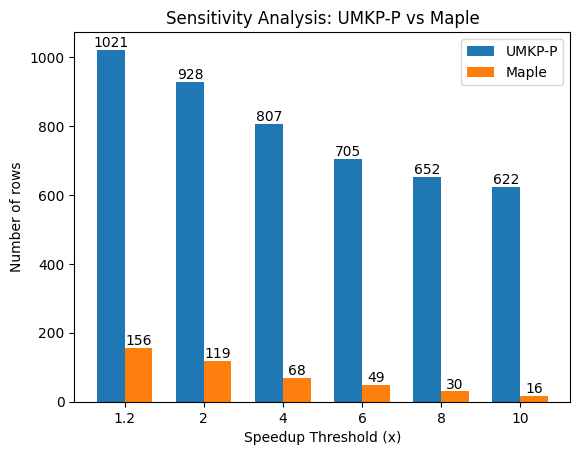

In [202]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[1.2, 2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     min_abs_diff=10.0,
                     max_len=25,
                     sort_by="speedup"):
    
    import matplotlib.pyplot as plt

    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    df = df.replace(0, 0.01)

    df_filtered = df[
        ((df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)) &
        ((df[col_a] - df[col_b]).abs() >= min_abs_diff)
    ].copy()

    df_filtered["abs_diff"] = (df_filtered[col_a] - df_filtered[col_b]).abs()
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    def sort_df(df_in, side):
        if sort_by == "speedup":
            key = "speedup_a" if side == "A" else "speedup_b"
        elif sort_by == "runtime":
            key = col_a if side == "A" else col_b
        elif sort_by == "abs_diff":
            key = "abs_diff"
        else:
            raise ValueError("sort_by must be 'speedup', 'runtime', or 'abs_diff'")
        return df_in.sort_values(by=key, ascending=False)

    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            # "abs_diff",
            # "UMKP+-oriented-S", "UMKP+-oriented-R", "UMKP+-oriented-P",
            "speedup"
        ]]

    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"Ignoring rows with |{col_a} - {col_b}| < {min_abs_diff}")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")
    print(f"Sorting by: {sort_by}")

    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(sort_df(a_wins, "A"), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(sort_df(b_wins, "B"), "B"))

    else:
        if weaker == "A":
            weaker_df = sort_df(a_wins, "A")
            stronger_df = sort_df(b_wins, "B")
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = sort_df(b_wins, "B")
            stronger_df = sort_df(a_wins, "A")
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()

# compare_speedups(df, "UMKP-S", "DiseMKP", min_abs_diff=10)
compare_speedups(df, "UMKP-P", "Maple", min_abs_diff=10)
# compare_speedups(df, "UMKP+-oriented-B", "kPlexT", min_abs_diff=10)
# compare_speedups(df, "CTCP-KPEX", "CFCTCP-KPEX", min_abs_diff=10)
# compare_speedups(df, "CTCP-KPEX", "CTCP-EGO", min_abs_diff=1)

# compare_speedups(df, "UMKP+-R", "UMKP-R", min_abs_diff=10)
# compare_speedups(df, "UMKP+-S", "UMKP+-oriented-S", min_abs_diff=10)
# compare_speedups(df, "kPEX-B", "kPEX-MB", min_abs_diff=10)
# compare_speedups(df, "UMKP+-oriented-B", "kPlexT", min_abs_diff=10)
# compare_speedups(df, "UMKP+-R", "UMKP+-oriented-R", min_abs_diff=10)
# compare_speedups(df, "kPEX-orig", "kPEX", min_abs_diff=10)


In [193]:
def compare_cols(df, col1, col2, extra_cols=("dataset", "k", "UMKP+-P"), ignore_value=1800):
    mask = (
        df[col1].notna() &
        df[col2].notna() &
        (df[col1] != ignore_value) &
        (df[col2] != ignore_value) &
        (df[col1] != df[col2])
    )
    return df.loc[mask, list(extra_cols) + [col1, col2]]
disp=compare_cols(df, "UMKP+-oriented-S-mkp", "UMKP+-oriented-B-mkp")
display_scroll(disp)


dataset,k,UMKP+-P,UMKP+-oriented-S-mkp,UMKP+-oriented-B-mkp


# Export best vs second best


This cell exports the global best-vs-second-best analysis for all configured algorithms, with one sheet per winning algorithm plus `Top2_by_ratio` and `Top2_by_abs_diff` summary sheets.



In [194]:
import pandas as pd
import numpy as np
from openpyxl.worksheet.table import Table as XLTable, TableStyleInfo
from openpyxl.styles import Font

all_algos = ['kPEX-S', 'kPEX-R', 'kPEX-P', 'kPEX-B',
             'UMKP-S', 'UMKP-R', 'UMKP-P', 'UMKP-B', 
             'UMKP+-S', 'UMKP+-R', 'UMKP+-P', 'UMKP+-B',
             'UMKP+-oriented-S', 'UMKP+-oriented-R', 'UMKP+-oriented-P', 'UMKP+-oriented-B',
            #  'UMKP-Imp', 'kPEX-Imp', 
            #  'Maple', 'DiseMKP', 'kPlexT'
             ]

meta_cols = ["dataset", "k", "n", "m", "d_avg", "d_max"]
vals = df[all_algos].apply(pd.to_numeric, errors="coerce")

def autofit_worksheet(ws, min_width=10, max_width=40):
    for column_cells in ws.columns:
        column_letter = column_cells[0].column_letter
        max_len = 0
        for cell in column_cells:
            if cell.value is not None:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[column_letter].width = min(max(max_len + 2, min_width), max_width)

def style_worksheet(ws, nrows, ncols, font_size=14):
    int_cols = {"k", "n", "m"}
    font = Font(size=font_size)

    for row in ws.iter_rows(min_row=1, max_row=nrows + 1, max_col=ncols):
        for cell in row:
            cell.font = font
            if cell.row >= 2 and isinstance(cell.value, (int, float)) and cell.column != 1:
                header = ws.cell(row=1, column=cell.column).value
                if header in int_cols:
                    cell.number_format = "0"
                elif header == "ratio":
                    cell.number_format = "0.00"
                else:
                    cell.number_format = "0.0"

    autofit_worksheet(ws)

def add_table_and_style(writer, sheet_name, nrows, ncols, table_name):
    ws = writer.book[sheet_name]
    if nrows <= 0 or ncols <= 0:
        return
    last_col = ws.cell(row=1, column=ncols).column_letter
    table_ref = f"A1:{last_col}{nrows + 1}"
    table = XLTable(displayName=table_name, ref=table_ref)
    style = TableStyleInfo(
        name="TableStyleMedium9",
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=False
    )
    table.tableStyleInfo = style
    ws.add_table(table)
    style_worksheet(ws, nrows, ncols)

output_path = "best_algo_vs_second_best.xlsx"
ratio_threshold = 1.1
summary_rows = []
summary_rows_abs = []
win_count_rows = []
sheet_results = []

overall_best = vals.min(axis=1)

for algo in all_algos:
    others = [c for c in all_algos if c != algo]
    second_best_time = vals[others].min(axis=1)
    second_best_algo = vals[others].idxmin(axis=1)

    is_best = vals[algo] == overall_best

    sheet_df = df.loc[is_best, meta_cols].copy()
    sheet_df[f"{algo}_time"] = vals.loc[is_best, algo]
    sheet_df["second_best_algo"] = second_best_algo.loc[is_best]
    sheet_df["second_best_time"] = second_best_time.loc[is_best]
    sheet_df["ratio"] = second_best_time.loc[is_best] / vals.loc[is_best, algo]
    sheet_df["abs_diff"] = second_best_time.loc[is_best] - vals.loc[is_best, algo]
    sheet_df = sheet_df.sort_values("ratio", ascending=False)

    win_count_rows.append({
        "best_algo": algo,
        "ratio_threshold": ratio_threshold,
        "win_count": int((sheet_df["ratio"] >= ratio_threshold).sum())
    })

    top2 = sheet_df.head(2).copy()
    if not top2.empty:
        top2.insert(0, "best_algo", algo)
        top2 = top2.rename(columns={f"{algo}_time": "best_time"})
        summary_rows.append(top2[[
            "dataset", "k", "n", "m", "d_avg", "d_max",
            "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
        ]])

    top2_abs = sheet_df.sort_values("abs_diff", ascending=False).head(2).copy()
    if not top2_abs.empty:
        top2_abs.insert(0, "best_algo", algo)
        top2_abs = top2_abs.rename(columns={f"{algo}_time": "best_time"})
        summary_rows_abs.append(top2_abs[[
            "dataset", "k", "n", "m", "d_avg", "d_max",
            "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
        ]])

    sheet_results.append((algo[:31], sheet_df))

summary_df = pd.concat(summary_rows, ignore_index=True) if summary_rows else pd.DataFrame()
summary_df_abs = pd.concat(summary_rows_abs, ignore_index=True) if summary_rows_abs else pd.DataFrame()
win_count_df = pd.DataFrame(win_count_rows) if win_count_rows else pd.DataFrame()

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    summary_sheet = "Top2_by_ratio"
    summary_df.to_excel(writer, sheet_name=summary_sheet, index=False)
    add_table_and_style(writer, summary_sheet, *summary_df.shape, "Table_Top2_by_ratio")

    summary_sheet_abs = "Top2_by_abs_diff"
    summary_df_abs.to_excel(writer, sheet_name=summary_sheet_abs, index=False)
    add_table_and_style(writer, summary_sheet_abs, *summary_df_abs.shape, "Table_Top2_by_abs_diff")

    win_count_sheet = "WinCount_ge_1_1x"
    win_count_df.to_excel(writer, sheet_name=win_count_sheet, index=False)
    add_table_and_style(writer, win_count_sheet, *win_count_df.shape, "Table_WinCount_ge_1_1x")

    for sheet_name, sheet_df in sheet_results:
        sheet_df.to_excel(writer, sheet_name=sheet_name, index=False)
        add_table_and_style(
            writer,
            sheet_name,
            *sheet_df.shape,
            f"Table_{sheet_name.replace('-', '_').replace('+', 'p')}"
        )

print(f"Wrote {output_path}")



Wrote best_algo_vs_second_best.xlsx


This cell exports the category-limited analysis, where winners and runner-ups are computed only within the `kPEX-*`, `UMKP-*`, and `UMKP+-*` families.



In [195]:
import pandas as pd
import numpy as np
from openpyxl.worksheet.table import Table as XLTable, TableStyleInfo
from openpyxl.styles import Font

all_algos = ['kPEX-S', 'kPEX-R', 'kPEX-P', 'kPEX-Imp', 
             'UMKP-S', 'UMKP-R', 'UMKP-P', 'UMKP-B', 
             'UMKP+-S', 'UMKP+-R', 'UMKP+-P', 'UMKP+-B', 
             'UMKP+-oriented-S', 'UMKP+-oriented-R', 'UMKP+-oriented-P', 'UMKP+-oriented-B', 
             ]
meta_cols = ["dataset", "k", "n", "m", "d_avg", "d_max"]
vals = df[all_algos].apply(pd.to_numeric, errors="coerce")

def autofit_worksheet(ws, min_width=10, max_width=40):
    for column_cells in ws.columns:
        column_letter = column_cells[0].column_letter
        max_len = 0
        for cell in column_cells:
            if cell.value is not None:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[column_letter].width = min(max(max_len + 2, min_width), max_width)

def style_worksheet(ws, nrows, ncols, font_size=14):
    int_cols = {"k", "n", "m"}
    font = Font(size=font_size)

    for row in ws.iter_rows(min_row=1, max_row=nrows + 1, max_col=ncols):
        for cell in row:
            cell.font = font
            if cell.row >= 2 and isinstance(cell.value, (int, float)) and cell.column != 1:
                header = ws.cell(row=1, column=cell.column).value
                if header in int_cols:
                    cell.number_format = "0"
                elif header == "ratio":
                    cell.number_format = "0.00"
                else:
                    cell.number_format = "0.0"

    autofit_worksheet(ws)

def add_table_and_style(writer, sheet_name, nrows, ncols, table_name):
    ws = writer.book[sheet_name]
    if nrows <= 0 or ncols <= 0:
        return
    last_col = ws.cell(row=1, column=ncols).column_letter
    table_ref = f"A1:{last_col}{nrows + 1}"
    table = XLTable(displayName=table_name, ref=table_ref)
    style = TableStyleInfo(
        name="TableStyleMedium9",
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=False
    )
    table.tableStyleInfo = style
    ws.add_table(table)
    style_worksheet(ws, nrows, ncols)

output_path = "best_algo_vs_second_best_by_category.xlsx"
ratio_threshold = 1.1
summary_rows = []
summary_rows_abs = []
win_count_rows = []
sheet_results = []

category_map = {
    "kPEX": [c for c in all_algos if c.startswith("kPEX-")],
    "UMKP": [c for c in all_algos if c.startswith("UMKP-") and not c.startswith("UMKP+-")],
    "UMKP+": [c for c in all_algos if c.startswith("UMKP+-") and not c.startswith("UMKP+-oriented")],
    "UMKP+-oriented": [c for c in all_algos if c.startswith("UMKP+-oriented")],
}

for category, cat_algos in category_map.items():
    cat_vals = vals[cat_algos]
    overall_best = cat_vals.min(axis=1)

    for algo in cat_algos:
        others = [c for c in cat_algos if c != algo]
        second_best_time = cat_vals[others].min(axis=1)
        second_best_algo = cat_vals[others].idxmin(axis=1)

        is_best = cat_vals[algo] == overall_best

        sheet_df = df.loc[is_best, meta_cols].copy()
        sheet_df["category"] = category
        sheet_df[f"{algo}_time"] = vals.loc[is_best, algo]
        sheet_df["second_best_algo"] = second_best_algo.loc[is_best]
        sheet_df["second_best_time"] = second_best_time.loc[is_best]
        sheet_df["ratio"] = second_best_time.loc[is_best] / vals.loc[is_best, algo]
        sheet_df["abs_diff"] = second_best_time.loc[is_best] - vals.loc[is_best, algo]
        sheet_df = sheet_df.sort_values("ratio", ascending=False)

        win_count_rows.append({
            "category": category,
            "best_algo": algo,
            "ratio_threshold": ratio_threshold,
            "win_count": int((sheet_df["ratio"] >= ratio_threshold).sum())
        })

        top2 = sheet_df.head(2).copy()
        if not top2.empty:
            top2.insert(0, "best_algo", algo)
            top2 = top2.rename(columns={f"{algo}_time": "best_time"})
            summary_rows.append(top2[[
                "dataset", "k", "n", "m", "d_avg", "d_max", "category",
                "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
            ]])

        top2_abs = sheet_df.sort_values("abs_diff", ascending=False).head(2).copy()
        if not top2_abs.empty:
            top2_abs.insert(0, "best_algo", algo)
            top2_abs = top2_abs.rename(columns={f"{algo}_time": "best_time"})
            summary_rows_abs.append(top2_abs[[
                "dataset", "k", "n", "m", "d_avg", "d_max", "category",
                "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
            ]])

        sheet_results.append((algo[:31], sheet_df))

summary_df = pd.concat(summary_rows, ignore_index=True) if summary_rows else pd.DataFrame()
summary_df_abs = pd.concat(summary_rows_abs, ignore_index=True) if summary_rows_abs else pd.DataFrame()
win_count_df = pd.DataFrame(win_count_rows) if win_count_rows else pd.DataFrame()

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    summary_sheet = "Top2_by_ratio"
    summary_df.to_excel(writer, sheet_name=summary_sheet, index=False)
    add_table_and_style(writer, summary_sheet, *summary_df.shape, "Table_Top2_by_ratio")

    summary_sheet_abs = "Top2_by_abs_diff"
    summary_df_abs.to_excel(writer, sheet_name=summary_sheet_abs, index=False)
    add_table_and_style(writer, summary_sheet_abs, *summary_df_abs.shape, "Table_Top2_by_abs_diff")

    win_count_sheet = "WinCount_ge_1_1x"
    win_count_df.to_excel(writer, sheet_name=win_count_sheet, index=False)
    add_table_and_style(writer, win_count_sheet, *win_count_df.shape, "Table_WinCount_ge_1_1x")

    for sheet_name, sheet_df in sheet_results:
        sheet_df.to_excel(writer, sheet_name=sheet_name, index=False)
        add_table_and_style(
            writer,
            sheet_name,
            *sheet_df.shape,
            f"Table_{sheet_name.replace('-', '_').replace('+', 'p')}"
        )

print(f"Wrote {output_path}")



Wrote best_algo_vs_second_best_by_category.xlsx


This cell exports the subset analysis for `kPlexT`, `DiseMKP`, and `Maple`, keeping only rows where a candidate beats the best non-candidate by at least 10 seconds.



In [196]:
import pandas as pd
import numpy as np
from openpyxl.worksheet.table import Table as XLTable, TableStyleInfo
from openpyxl.styles import Font
all_algos = ['kPEX-S', 'kPEX-R', 'kPEX-P', 'kPEX-B',
             'UMKP-S', 'UMKP-R', 'UMKP-P', 'UMKP-B', 
             'UMKP+-S', 'UMKP+-R', 'UMKP+-P', 'UMKP+-B', 
            'UMKP+-oriented-S', 'UMKP+-oriented-R', 'UMKP+-oriented-P','UMKP+-oriented-B',
             'UMKP-Imp', 'kPEX-Imp', 
             'Maple', 'DiseMKP', 'kPlexT'
             ]
candidate_algos = ["kPlexT", "DiseMKP", "Maple"]
comparison_algos = [c for c in all_algos if c not in candidate_algos]
meta_cols = ["dataset", "k", "n", "m", "d_avg", "d_max"]
vals_candidates = df[candidate_algos].apply(pd.to_numeric, errors="coerce")
vals_all = df[comparison_algos].apply(pd.to_numeric, errors="coerce")

def autofit_worksheet(ws, min_width=10, max_width=40):
    for column_cells in ws.columns:
        column_letter = column_cells[0].column_letter
        max_len = 0
        for cell in column_cells:
            if cell.value is not None:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[column_letter].width = min(max(max_len + 2, min_width), max_width)

def style_worksheet(ws, nrows, ncols, font_size=14):
    int_cols = {"k", "n", "m"}
    font = Font(size=font_size)

    for row in ws.iter_rows(min_row=1, max_row=nrows + 1, max_col=ncols):
        for cell in row:
            cell.font = font
            if cell.row >= 2 and isinstance(cell.value, (int, float)) and cell.column != 1:
                header = ws.cell(row=1, column=cell.column).value
                if header in int_cols:
                    cell.number_format = "0"
                elif header == "ratio":
                    cell.number_format = "0.00"
                else:
                    cell.number_format = "0.0"

    autofit_worksheet(ws)

def add_table_and_style(writer, sheet_name, nrows, ncols, table_name):
    ws = writer.book[sheet_name]
    if nrows <= 0 or ncols <= 0:
        return
    last_col = ws.cell(row=1, column=ncols).column_letter
    table_ref = f"A1:{last_col}{nrows + 1}"
    table = XLTable(displayName=table_name, ref=table_ref)
    style = TableStyleInfo(
        name="TableStyleMedium9",
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=False
    )
    table.tableStyleInfo = style
    ws.add_table(table)
    style_worksheet(ws, nrows, ncols)

output_path = "best_of_maple_disemkp_kplext_vs_all.xlsx"
min_abs_diff = 1.0
ratio_threshold = 1.1
summary_rows = []
summary_rows_abs = []
win_count_rows = []
sheet_results = []

best_non_candidate_time = vals_all.min(axis=1)

for algo in candidate_algos:
    second_best_time = vals_all.min(axis=1)
    second_best_algo = vals_all.idxmin(axis=1)

    abs_diff_series = best_non_candidate_time - vals_candidates[algo]
    is_best = (vals_candidates[algo] < best_non_candidate_time) & (abs_diff_series >= min_abs_diff)

    sheet_df = df.loc[is_best, meta_cols].copy()
    sheet_df[f"{algo}_time"] = vals_candidates.loc[is_best, algo]
    sheet_df["second_best_algo"] = second_best_algo.loc[is_best]
    sheet_df["second_best_time"] = second_best_time.loc[is_best]
    sheet_df["ratio"] = second_best_time.loc[is_best] / vals_candidates.loc[is_best, algo]
    sheet_df["abs_diff"] = second_best_time.loc[is_best] - vals_candidates.loc[is_best, algo]
    sheet_df = sheet_df.sort_values("ratio", ascending=False)

    win_count_rows.append({
        "best_algo": algo,
        "ratio_threshold": ratio_threshold,
        "win_count": int((sheet_df["ratio"] >= ratio_threshold).sum())
    })

    top2 = sheet_df.head(2).copy()
    if not top2.empty:
        top2.insert(0, "best_algo", algo)
        top2 = top2.rename(columns={f"{algo}_time": "best_time"})
        summary_rows.append(top2[[
            "dataset", "k", "n", "m", "d_avg", "d_max",
            "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
        ]])

    top2_abs = sheet_df.sort_values("abs_diff", ascending=False).head(2).copy()
    if not top2_abs.empty:
        top2_abs.insert(0, "best_algo", algo)
        top2_abs = top2_abs.rename(columns={f"{algo}_time": "best_time"})
        summary_rows_abs.append(top2_abs[[
            "dataset", "k", "n", "m", "d_avg", "d_max",
            "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
        ]])

    sheet_results.append((algo[:31], sheet_df))

summary_df = pd.concat(summary_rows, ignore_index=True) if summary_rows else pd.DataFrame()
summary_df_abs = pd.concat(summary_rows_abs, ignore_index=True) if summary_rows_abs else pd.DataFrame()
win_count_df = pd.DataFrame(win_count_rows) if win_count_rows else pd.DataFrame()

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    summary_sheet = "Top2_by_ratio"
    summary_df.to_excel(writer, sheet_name=summary_sheet, index=False)
    add_table_and_style(writer, summary_sheet, *summary_df.shape, "Table_Top2_by_ratio")

    summary_sheet_abs = "Top2_by_abs_diff"
    summary_df_abs.to_excel(writer, sheet_name=summary_sheet_abs, index=False)
    add_table_and_style(writer, summary_sheet_abs, *summary_df_abs.shape, "Table_Top2_by_abs_diff")

    win_count_sheet = "WinCount_ge_1_1x"
    win_count_df.to_excel(writer, sheet_name=win_count_sheet, index=False)
    add_table_and_style(writer, win_count_sheet, *win_count_df.shape, "Table_WinCount_ge_1_1x")

    for sheet_name, sheet_df in sheet_results:
        sheet_df.to_excel(writer, sheet_name=sheet_name, index=False)
        add_table_and_style(
            writer,
            sheet_name,
            *sheet_df.shape,
            f"Table_{sheet_name.replace('-', '_').replace('+', 'p')}"
        )

print(f"Wrote {output_path}")



Wrote best_of_maple_disemkp_kplext_vs_all.xlsx


This cell exports branch-scheme comparisons, where each algorithm is compared only against algorithms with the same scheme suffix, e.g. `kPEX-S` vs `UMKP-S`, `UMKP+-S`, and `UMKP+-oriented-S`, with the `B` scheme including `UMKP-B` too.



In [197]:
import pandas as pd
import numpy as np
from openpyxl.worksheet.table import Table as XLTable, TableStyleInfo
from openpyxl.styles import Font

scheme_groups = {
    'S': ['kPEX-S', 'UMKP-S', 'UMKP+-S', 'UMKP+-oriented-S'],
    'R': ['kPEX-R', 'UMKP-R', 'UMKP+-R', 'UMKP+-oriented-R'],
    'P': ['kPEX-P', 'UMKP-P', 'UMKP+-P', 'UMKP+-oriented-P'],
    'B': ['kPEX-B', 'UMKP-B', 'UMKP+-B', 'UMKP+-oriented-B'],
}
meta_cols = ["dataset", "k", "n", "m", "d_avg", "d_max"]

available_groups = {
    scheme: [algo for algo in algos if algo in df.columns]
    for scheme, algos in scheme_groups.items()
}
available_groups = {scheme: algos for scheme, algos in available_groups.items() if len(algos) >= 2}

missing_algos = sorted({algo for algos in scheme_groups.values() for algo in algos if algo not in df.columns})
if missing_algos:
    print("Skipping missing columns:", ", ".join(missing_algos))

scheme_algos = [algo for algos in available_groups.values() for algo in algos]
if not scheme_algos:
    raise ValueError("No branch-scheme groups have at least two available algorithm columns.")

vals = df[scheme_algos].apply(pd.to_numeric, errors="coerce")

def autofit_worksheet(ws, min_width=10, max_width=40):
    for column_cells in ws.columns:
        column_letter = column_cells[0].column_letter
        max_len = 0
        for cell in column_cells:
            if cell.value is not None:
                max_len = max(max_len, len(str(cell.value)))
        ws.column_dimensions[column_letter].width = min(max(max_len + 2, min_width), max_width)

def style_worksheet(ws, nrows, ncols, font_size=14):
    int_cols = {"k", "n", "m"}
    font = Font(size=font_size)

    for row in ws.iter_rows(min_row=1, max_row=nrows + 1, max_col=ncols):
        for cell in row:
            cell.font = font
            if cell.row >= 2 and isinstance(cell.value, (int, float)) and cell.column != 1:
                header = ws.cell(row=1, column=cell.column).value
                if header in int_cols:
                    cell.number_format = "0"
                elif header == "ratio":
                    cell.number_format = "0.00"
                else:
                    cell.number_format = "0.0"

    autofit_worksheet(ws)

def add_table_and_style(writer, sheet_name, nrows, ncols, table_name):
    ws = writer.book[sheet_name]
    if nrows <= 0 or ncols <= 0:
        return
    last_col = ws.cell(row=1, column=ncols).column_letter
    table_ref = f"A1:{last_col}{nrows + 1}"
    table = XLTable(displayName=table_name, ref=table_ref)
    style = TableStyleInfo(
        name="TableStyleMedium9",
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=False
    )
    table.tableStyleInfo = style
    ws.add_table(table)
    style_worksheet(ws, nrows, ncols)

output_path = "best_algo_vs_second_best_by_branch_scheme.xlsx"
ratio_threshold = 1.1
summary_rows = []
summary_rows_abs = []
win_count_rows = []
sheet_results = []

for scheme, algos in available_groups.items():
    scheme_vals = vals[algos]
    scheme_best = scheme_vals.min(axis=1)

    for algo in algos:
        others = [c for c in algos if c != algo]
        second_best_time = scheme_vals[others].min(axis=1)
        second_best_algo = scheme_vals[others].idxmin(axis=1)

        is_best = scheme_vals[algo] == scheme_best

        sheet_df = df.loc[is_best, meta_cols].copy()
        sheet_df["scheme"] = scheme
        sheet_df[f"{algo}_time"] = vals.loc[is_best, algo]
        sheet_df["second_best_algo"] = second_best_algo.loc[is_best]
        sheet_df["second_best_time"] = second_best_time.loc[is_best]
        sheet_df["ratio"] = second_best_time.loc[is_best] / vals.loc[is_best, algo]
        sheet_df["abs_diff"] = second_best_time.loc[is_best] - vals.loc[is_best, algo]
        sheet_df = sheet_df.sort_values("ratio", ascending=False)

        win_count_rows.append({
            "scheme": scheme,
            "best_algo": algo,
            "ratio_threshold": ratio_threshold,
            "win_count": int((sheet_df["ratio"] >= ratio_threshold).sum())
        })

        top2 = sheet_df.head(2).copy()
        if not top2.empty:
            top2.insert(0, "best_algo", algo)
            top2 = top2.rename(columns={f"{algo}_time": "best_time"})
            summary_rows.append(top2[[
                "dataset", "k", "n", "m", "d_avg", "d_max", "scheme",
                "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
            ]])

        top2_abs = sheet_df.sort_values("abs_diff", ascending=False).head(2).copy()
        if not top2_abs.empty:
            top2_abs.insert(0, "best_algo", algo)
            top2_abs = top2_abs.rename(columns={f"{algo}_time": "best_time"})
            summary_rows_abs.append(top2_abs[[
                "dataset", "k", "n", "m", "d_avg", "d_max", "scheme",
                "best_algo", "best_time", "second_best_algo", "second_best_time", "ratio", "abs_diff"
            ]])

        sheet_results.append((algo[:31], sheet_df))

summary_df = pd.concat(summary_rows, ignore_index=True) if summary_rows else pd.DataFrame()
summary_df_abs = pd.concat(summary_rows_abs, ignore_index=True) if summary_rows_abs else pd.DataFrame()
win_count_df = pd.DataFrame(win_count_rows) if win_count_rows else pd.DataFrame()

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    summary_sheet = "Top2_by_ratio"
    summary_df.to_excel(writer, sheet_name=summary_sheet, index=False)
    add_table_and_style(writer, summary_sheet, *summary_df.shape, "Table_Top2_by_ratio")

    summary_sheet_abs = "Top2_by_abs_diff"
    summary_df_abs.to_excel(writer, sheet_name=summary_sheet_abs, index=False)
    add_table_and_style(writer, summary_sheet_abs, *summary_df_abs.shape, "Table_Top2_by_abs_diff")

    win_count_sheet = "WinCount_ge_1_1x"
    win_count_df.to_excel(writer, sheet_name=win_count_sheet, index=False)
    add_table_and_style(writer, win_count_sheet, *win_count_df.shape, "Table_WinCount_ge_1_1x")

    for sheet_name, sheet_df in sheet_results:
        sheet_df.to_excel(writer, sheet_name=sheet_name, index=False)
        add_table_and_style(
            writer,
            sheet_name,
            *sheet_df.shape,
            f"Table_{sheet_name.replace('-', '_').replace('+', 'p')}"
        )

print(f"Wrote {output_path}")



Wrote best_algo_vs_second_best_by_branch_scheme.xlsx
